# 02 — Análise exploratória e pré-processamento

**Trabalho 2 – Previsão do PIB dos Municípios da Região Sul (PR, SC, RS)**

Entrada: `data/processed/painel_municipios.csv`, gerado pelo notebook 01.
Saídas: `data/processed/dataset_tratado.csv` e `data/processed/dicionario_dataset.csv`.

Este notebook:
1. **verifica a qualidade dos dados** (ausentes, duplicados, inconsistências e quebras de série) e aplica os tratamentos;
2. faz a **análise exploratória**: distribuição do PIB, crescimento ao longo do tempo, desbalanceamento das categorias e relações entre variáveis;
3. constrói as **variáveis explicativas**, respeitando o que estaria disponível no momento da previsão;
4. define o **pré-processamento** (imputação, padronização e codificação de categóricas) que os modelos vão usar.

A lógica fica em `src/features.py`, para que os notebooks de modelagem usem exatamente as mesmas transformações.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import features as ft
from src import viz
from src.integracao import ARQ_PAINEL

viz.aplica_estilo()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

painel = pd.read_csv(ARQ_PAINEL)
print(f"Painel: {painel.shape[0]:,} linhas × {painel.shape[1]} colunas")

Painel: 27,393 linhas × 105 colunas


## 1. Qualidade dos dados

### 1.1 Valores ausentes

Contamos os ausentes por bloco no período de interesse (2013–2024), antes do tratamento.

In [2]:
recorte = painel[painel["ano"].between(2013, 2024)]
blocos = {
    "PIB (2013–2023)": recorte.loc[recorte["ano"] <= 2023, ["pib"]],
    "VAB/impostos (2013–2021)": recorte.loc[recorte["ano"] <= 2021, ["vab_total", "vab_agro", "vab_industria", "vab_servicos", "vab_adm_publica", "impostos"]],
    "PAM": recorte.filter(like="pam_"),
    "PPM": recorte.filter(like="ppm_"),
    "População": recorte[["populacao"]],
    "PIA/PAS (UF)": recorte.filter(like="uf_p"),
}
pd.DataFrame({
    "células": {k: v.size for k, v in blocos.items()},
    "ausentes": {k: int(v.isna().sum().sum()) for k, v in blocos.items()},
}).assign(pct=lambda d: 100 * d["ausentes"] / d["células"])

,células,ausentes,pct
PIB (2013–2023),13101,0,0.000
VAB/impostos (2013–2021),64314,0,0.000
PAM,614556,2193,0.357
PPM,328716,23,0.007
População,14292,0,0.000
PIA/PAS (UF),142920,0,0.000


Os únicos ausentes no período estão na **PAM** e vêm de 6 municípios urbanos ou litorâneos (ver notebook 01).
O tratamento, em `ft.trata_ausentes_agro`, segue duas regras:

1. **Lacunas internas**, com dado antes e depois, são **interpoladas linearmente**. Ex.: Governador Celso Ramos (2020–2022) e Imbé (2020).
2. **Lacunas no fim ou no início da série** e municípios **sem nenhum dado** viram **zero**. Ex.: Balneário Camboriú, Bombinhas, Cachoeirinha. Neles o IBGE não publica produção agrícola porque ela é inexistente ou irrelevante.

As linhas imputadas ficam marcadas na coluna `agro_imputado`.

In [3]:
tratado = ft.trata_ausentes_agro(painel)
cols_agro = [c for c in painel.columns if c.startswith(("pam_", "ppm_"))]
antes = painel.loc[painel["ano"].between(2013, 2024), cols_agro].isna().sum().sum()
depois = tratado.loc[tratado["ano"].between(2013, 2024), cols_agro].isna().sum().sum()
print(f"Ausentes em PAM/PPM (2013–2024): antes = {antes:,} | depois = {depois:,}")

exemplo = tratado[tratado["cod_ibge"] == 4206009].set_index("ano").loc[2018:2024, ["municipio", "pam_valor_total", "agro_imputado"]]
exemplo  # Governador Celso Ramos: 2020–2022 interpolados

Ausentes em PAM/PPM (2013–2024): antes = 2,216 | depois = 0


,municipio,pam_valor_total,agro_imputado
ano,,,
2018,Governador Celso Ramos,38.000,0
2019,Governador Celso Ramos,23.000,0
2020,Governador Celso Ramos,107.250,1
2021,Governador Celso Ramos,191.500,1
2022,Governador Celso Ramos,275.750,1
2023,Governador Celso Ramos,360.000,0
2024,Governador Celso Ramos,436.000,0


### 1.2 Duplicados

In [4]:
print("Duplicados (cod_ibge, ano) no painel:", painel.duplicated(["cod_ibge", "ano"]).sum())
print("Linhas idênticas no painel:", painel.duplicated().sum())
print("Municípios distintos:", painel["cod_ibge"].nunique(), "| nomes distintos por UF:",
      painel.drop_duplicates("cod_ibge").duplicated(["municipio", "uf"]).sum(), "repetidos")

Duplicados (cod_ibge, ano) no painel: 0
Linhas idênticas no painel: 0
Municípios distintos: 1191 | nomes distintos por UF: 0 repetidos


### 1.3 Inconsistências

**(a) Identidades contábeis.** No notebook 01, PIB = VAB + impostos e VAB = soma dos setores fecharam com diferença máxima de 1–2 mil reais, só arredondamento.

**(b) Valores negativos.** Só aparecem no VAB da indústria:

In [5]:
painel.loc[painel["vab_industria"] < 0, ["municipio", "uf", "ano", "vab_industria", "vab_total", "pib"]]

,municipio,uf,ano,vab_industria,vab_total,pib
493,Araucária,PR,2012,"-560,800.000","3,986,171.000","5,721,493.000"
494,Araucária,PR,2013,"-246,380.000","4,741,312.000","6,838,315.000"
17720,Candiota,RS,2012,"-20,191.000","86,140.000","117,389.000"
17721,Candiota,RS,2013,"-41,309.000","95,724.000","116,696.000"


São **Araucária (PR)**, sede da refinaria REPAR, e **Candiota (RS)**, com a termelétrica a carvão, em 2012–2013.
O VAB negativo é **legítimo**: o consumo intermediário da atividade superou o valor da produção. Por isso o valor é **mantido**.
Como a participação setorial entra com defasagem de 3 anos, esses casos só afetam os alvos de 2015–2016.

**(c) Crescimentos extremos.** Calculamos o crescimento anual do PIB de cada município:

In [6]:
p = painel.sort_values(["cod_ibge", "ano"]).copy()
p["cresc_pct"] = (p["pib"] / p.groupby("cod_ibge")["pib"].shift(1) - 1) * 100
amostra = p[p["ano"].between(2013, 2023)]

display(amostra["cresc_pct"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("crescimento %").T)

extremos = amostra.nlargest(8, "cresc_pct")[["municipio", "uf", "ano", "pib", "cresc_pct"]]
extremos["cresc_ano_seguinte_pct"] = [
    p.loc[(p["cod_ibge"] == c) & (p["ano"] == a + 1), "cresc_pct"].squeeze() if a < 2023 else np.nan
    for c, a in zip(amostra.loc[extremos.index, "cod_ibge"], extremos["ano"])
]
extremos

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
crescimento %,"13,098.000",10.618,18.303,-65.956,-28.334,-11.102,1.755,8.661,16.622,37.980,73.490,392.580


,municipio,uf,ano,pib,cresc_pct,cresc_ano_seguinte_pct
24071,Roque Gonzales,RS,2015,"572,728.000",392.580,6.941
16159,Alpestre,RS,2015,"535,451.000",340.555,-16.300
6341,Pontal do Paraná,PR,2018,"2,425,080.000",319.590,-63.152
8459,Tamarana,PR,2020,"1,150,218.000",284.077,-65.956
17039,Boa Vista do Incra,RS,2021,"384,174.000",206.332,-49.333
21133,Jari,RS,2021,"469,006.000",202.774,-48.868
21018,Jacuizinho,RS,2021,"224,027.000",192.842,-49.207
20672,Imigrante,RS,2020,"742,320.000",182.220,-30.058


Os saltos acima de +100% são municípios pequenos com **grandes empreendimentos pontuais**, como usinas hidrelétricas, estaleiros e parques eólicos em construção, e quase sempre **revertem no ano seguinte**.
Os valores são reais, publicados pelo IBGE, então **não removemos** essas observações. Dois cuidados:
- a variável `cresc_pib_l1` (crescimento do ano anterior) dá ao modelo a informação de que houve um salto e de que ele tende a reverter;
- para os modelos lineares, o alvo de treino em log (`cresc_pib_log`) já comprime esses extremos. Na Fase 4 avaliamos também métodos robustos a outliers.

### 1.4 Quebras de série da população

As estimativas anuais do IBGE são projeções. Quando sai um novo censo, a série "salta" para o valor recenseado.

In [7]:
pop_sul = painel.groupby("ano")["populacao"].sum()
var_bruta = np.log(pop_sul).diff() * 100

# Dataset de modelagem completo (usado também nas seções seguintes)
dataset, dicionario = ft.constroi_dataset(painel)

# Variação ajustada da região: média das variações municipais ponderada pela população
validos = dataset.dropna(subset=["var_populacao", "log_populacao"])
var_ajustada = validos.groupby("ano").apply(
    lambda d: np.average(d["var_populacao"], weights=np.exp(d["log_populacao"])) * 100
)
pd.DataFrame({"variação bruta (%)": var_bruta, "variação ajustada (%)": var_ajustada}).loc[2008:2024].T

ano,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
variação bruta (%),2.819,0.801,-1.206,0.639,0.612,3.765,0.762,0.735,0.714,0.695,0.367,0.743,0.719,0.694,-1.541,1.921,1.930
variação ajustada (%),0.763,0.804,0.858,0.642,0.538,0.681,0.766,0.738,0.717,0.697,0.393,0.747,0.723,0.697,0.813,0.813,0.813


Entre a estimativa de 2021 e o Censo 2022, a população do Sul parece **cair 1,5%**, mas isso é correção de base, não perda real.
O mesmo vale no sentido contrário em **2013**, quando as estimativas foram recalibradas pelo Censo 2010 e a população "cresce" 3,8% de um ano para o outro, e em **2008**, depois da Contagem 2007.

Em `ft.populacao_ajustada`, a variação nesses anos (2008, 2010, 2013 e 2022) é substituída pela **taxa média anual entre os levantamentos oficiais que cercam o ano** (2007→2010 ou 2010→2022).

Por fim, **2023 e 2024** também crescem demais na série bruta, cerca de 1,9% ao ano contra cerca de 0,7% em 2010–2022. A estimativa de 2024 do IBGE já incorpora o **ajuste de cobertura do Censo 2022**, que corrige a subenumeração, e 2023 é interpolado entre o censo e essa estimativa.
Como 2024 é o ano a prever, essa variável ficaria fora do padrão do treino. Por isso, descontamos o **excesso médio da região** e preservamos as diferenças de crescimento entre municípios.
Para 2023 e 2024 vale a interpolação geométrica descrita no notebook 01.

## 2. Análise exploratória

### 2.1 Distribuição do PIB municipal

In [8]:
pib23 = painel[painel["ano"] == 2023][["municipio", "uf", "pib", "populacao"]].copy()
pib23["pib_bi"] = pib23["pib"] / 1e6

top = pib23.nlargest(10, "pib")[["municipio", "uf", "pib_bi"]]
top["participacao_%"] = 100 * top["pib_bi"] / pib23["pib_bi"].sum()
print(f"Assimetria do PIB 2023: {pib23['pib'].skew():.1f} (log: {np.log(pib23['pib']).skew():.2f})")
print(f"Os 10 maiores municípios concentram {top['participacao_%'].sum():.1f}% do PIB do Sul; "
      f"a mediana municipal é R$ {pib23['pib'].median() / 1e3:,.0f} milhões")
top

Assimetria do PIB 2023: 12.9 (log: 0.93)
Os 10 maiores municípios concentram 28.2% do PIB do Sul; a mediana municipal é R$ 355 milhões


,municipio,uf,pib_bi,participacao_%
2160,Curitiba,PR,120.065,6.545
23458,Porto Alegre,RS,104.743,5.710
12326,Joinville,SC,49.816,2.716
12073,Itajaí,SC,48.196,2.627
18168,Caxias do Sul,RS,37.861,2.064
504,Araucária,PR,34.075,1.858
8048,São José dos Pinhais,PR,33.958,1.851
11199,Florianópolis,SC,31.190,1.700
17800,Canoas,RS,29.167,1.590
4391,Londrina,PR,28.000,1.526


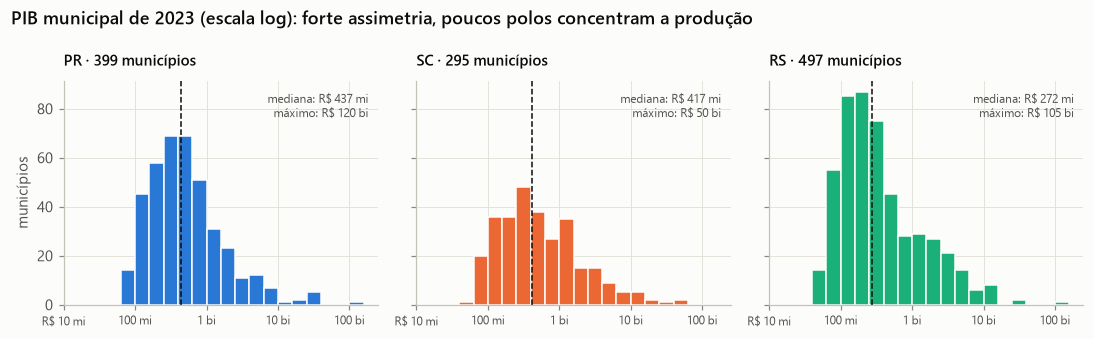

In [9]:
fig, eixos = plt.subplots(1, 3, figsize=(10, 3.1), sharex=True, sharey=True)
bins = np.arange(7.0, 11.41, 0.2)  # log10 do PIB em reais: de R$ 10 milhões a ~R$ 250 bilhões
for ax, uf in zip(eixos, ["PR", "SC", "RS"]):
    v = np.log10(pib23.loc[pib23["uf"] == uf, "pib"] * 1000)  # pib está em mil R$
    assert v.between(bins[0], bins[-1]).all(), "há municípios fora das faixas do histograma"
    ax.hist(v, bins=bins, color=viz.CORES_UF[uf], edgecolor=viz.SUPERFICIE, linewidth=1)
    ax.axvline(v.median(), color=viz.TINTA, lw=1, ls="--")
    ax.text(0.97, 0.95, f"mediana: R$ {10 ** v.median() / 1e6:,.0f} mi\nmáximo: R$ {10 ** v.max() / 1e9:,.0f} bi",
            transform=ax.transAxes, ha="right", va="top", fontsize=8, color=viz.TINTA_SECUNDARIA)
    ax.set_title(f"{uf} · {len(v)} municípios", fontsize=10)
eixos[0].set_ylabel("municípios")
for ax in eixos:
    ax.set_xticks([7, 8, 9, 10, 11])
    ax.set_xticklabels(["R$ 10 mi", "100 mi", "1 bi", "10 bi", "100 bi"], fontsize=8)
    ax.set_xlim(bins[0], bins[-1])
fig.suptitle("PIB municipal de 2023 (escala log): forte assimetria, poucos polos concentram a produção",
             x=0.01, ha="left", fontsize=11.5, fontweight="semibold")
fig.tight_layout()
viz.salva_figura(fig, "eda_distribuicao_pib_2023")
plt.show()

### 2.2 Crescimento do PIB ao longo do tempo

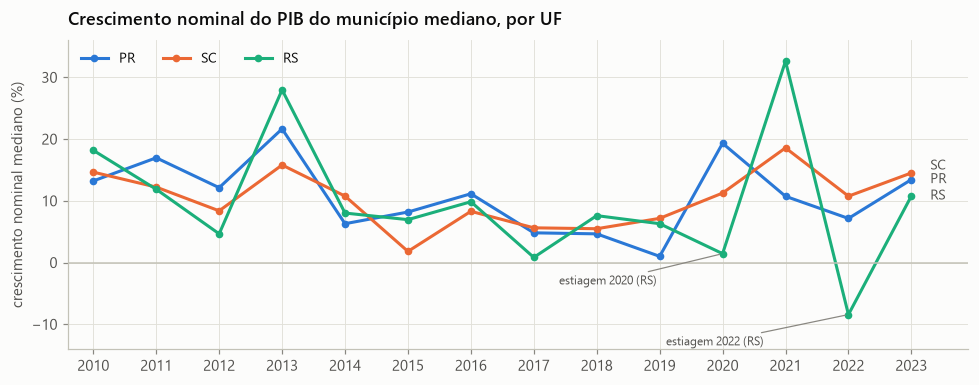

Crescimento nominal do PIB agregado de cada UF (%):


ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
uf,,,,,,,,,,,,,,
PR,14.500,14.200,11.100,16.800,4.400,8.300,6.600,4.900,4.400,6.000,4.600,12.700,11.800,9.200
SC,19.100,13.200,10.200,11.800,13.100,2.700,3.100,8.000,7.600,8.400,8.000,22.700,8.800,10.100
RS,18.100,9.900,8.500,15.500,7.700,6.800,7.000,3.500,8.000,5.500,-2.400,23.400,2.100,9.500


In [10]:
cresc_uf = (p[p["ano"].between(2010, 2023)]
            .groupby(["ano", "uf"])["cresc_pct"].median().unstack("uf")[["PR", "SC", "RS"]])
agregado = painel.groupby(["ano", "uf"])["pib"].sum().unstack("uf")
cresc_agregado = (agregado.pct_change() * 100).loc[2010:2023, ["PR", "SC", "RS"]]

fig, ax = plt.subplots(figsize=(9, 3.6))
for uf in ["PR", "SC", "RS"]:
    ax.plot(cresc_uf.index, cresc_uf[uf], color=viz.CORES_UF[uf], marker="o", ms=4, label=uf)
# Rótulos diretos no fim das linhas, afastados para não se sobreporem
fim = cresc_uf.loc[2023].sort_values()
posicoes = {}
for uf, v in fim.items():
    y = v if not posicoes else max(v, max(posicoes.values()) + 2.2)
    posicoes[uf] = y
    ax.text(2023.3, y, uf, color=viz.TINTA_SECUNDARIA, va="center", fontsize=9)
ax.axhline(0, color=viz.EIXO, lw=1)
ax.set_xticks(range(2010, 2024))
ax.set_xlim(2009.6, 2023.9)
ax.set_ylim(-14, 36)
ax.set_ylabel("crescimento nominal mediano (%)")
ax.legend(loc="upper left", ncol=3)
for ano, texto, dx in [(2022, "estiagem 2022 (RS)", -2.9), (2020, "estiagem 2020 (RS)", -2.6)]:
    ax.annotate(texto, xy=(ano, cresc_uf.loc[ano, "RS"]), xytext=(ano + dx, cresc_uf.loc[ano, "RS"] - 4.5),
                fontsize=8, color=viz.TINTA_SECUNDARIA, va="center",
                arrowprops=dict(arrowstyle="-", color=viz.TINTA_SUAVE, lw=0.8))
ax.set_title("Crescimento nominal do PIB do município mediano, por UF")
fig.tight_layout()
viz.salva_figura(fig, "eda_crescimento_mediano_uf")
plt.show()

print("Crescimento nominal do PIB agregado de cada UF (%):")
cresc_agregado.T.round(1)

### 2.3 Categorias de crescimento: desbalanceamento e variação entre anos

Aplicamos a definição do enunciado (`ft.categoriza_crescimento`) ao crescimento observado.

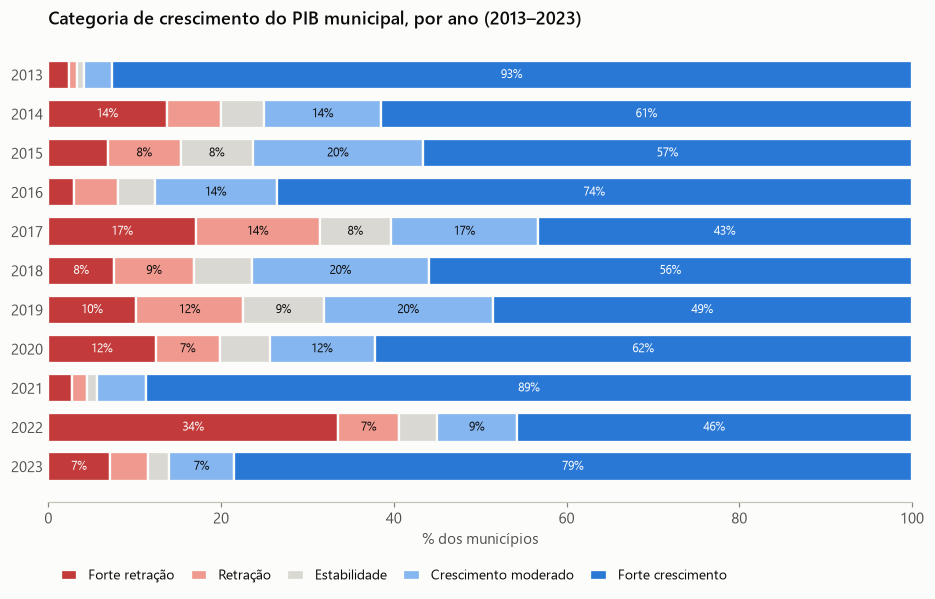

categoria,Forte retração,Retração,Estabilidade,Crescimento moderado,Forte crescimento
% no período 2013–2023,10.612,7.032,5.146,12.926,64.285


In [11]:
amostra = amostra.assign(categoria=ft.categoriza_crescimento(amostra["cresc_pct"]))
tab_cat = pd.crosstab(amostra["ano"], amostra["categoria"], normalize="index") * 100
tab_cat = tab_cat.reindex(columns=ft.CATEGORIAS)

ax = viz.barras_categorias_por_ano(tab_cat, titulo="Categoria de crescimento do PIB municipal, por ano (2013–2023)")
fig = ax.figure
fig.tight_layout()
viz.salva_figura(fig, "fig_categorias_por_ano")
plt.show()

total = amostra["categoria"].value_counts(normalize=True).reindex(ft.CATEGORIAS) * 100
total.to_frame("% no período 2013–2023").T

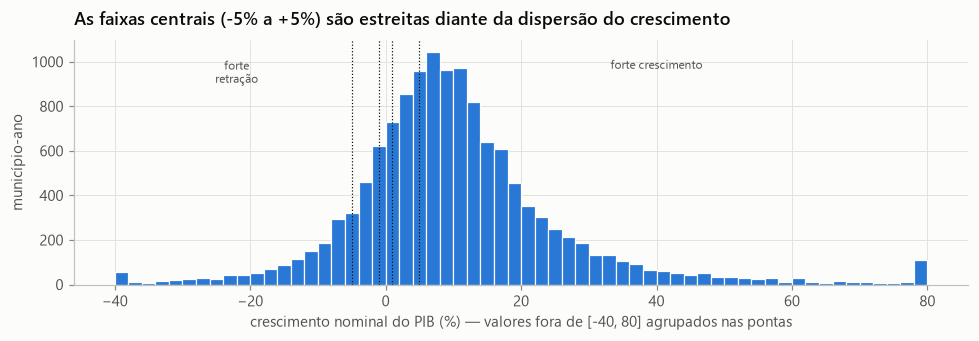

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.2))
x = amostra["cresc_pct"].clip(-40, 80)
ax.hist(x, bins=np.arange(-40, 80.5, 2), color=viz.RAMPA_AZUL[4], edgecolor=viz.SUPERFICIE, linewidth=0.8)
for lim in [-5, -1, 1, 5]:
    ax.axvline(lim, color=viz.TINTA, lw=0.8, ls=":")
ax.text(-22, ax.get_ylim()[1] * 0.92, "forte\nretração", ha="center", fontsize=8, color=viz.TINTA_SECUNDARIA, va="top")
ax.text(40, ax.get_ylim()[1] * 0.92, "forte crescimento", ha="center", fontsize=8, color=viz.TINTA_SECUNDARIA, va="top")
ax.set_xlabel("crescimento nominal do PIB (%) — valores fora de [-40, 80] agrupados nas pontas")
ax.set_ylabel("município-ano")
ax.set_title("As faixas centrais (-5% a +5%) são estreitas diante da dispersão do crescimento")
fig.tight_layout()
plt.show()

### 2.4 Relações entre as variáveis explicativas e o crescimento do PIB

Usamos a **correlação de Spearman**, baseada em postos, que é robusta aos extremos e capta relações monotônicas não lineares, entre cada variável e o alvo de treino `cresc_pib_log`, na amostra de treino (alvos de 2013 a 2022).

In [13]:
numericas, categoricas = ft.colunas_modelo(dataset)
treino = dataset[(dataset["amostra_padrao"] == 1) & (dataset["conjunto"] == "treino")]

corr_alvo = treino[numericas + ["cresc_pib_log"]].corr(method="spearman")["cresc_pib_log"].drop("cresc_pib_log")
corr_alvo = corr_alvo.reindex(corr_alvo.abs().sort_values(ascending=False).index)
corr_alvo.to_frame("Spearman com cresc_pib_log").T.round(2)

,choque_pam,var_pam_valor,choque_pam_reg_imediata,choque_soja,choque_pam_uf,choque_ppm_uf,choque_milho,cresc_pib_l1,var_uf_pia_pessoal_ocupado,choque_ppm_reg_imediata,choque_ppm,var_uf_pia_valor_transformacao,choque_trigo,var_ppm_valor,log_pib_pc_l1,var_uf_pia_receita_liquida,cresc_pib_reg_imediata_l1,pam_valor_sobre_pib_l1,choque_fumo,choque_arroz,cresc_pib_media_3a,var_uf_pas_pessoal_ocupado,var_uf_pas_receita_bruta,log_pib_l1,cresc_pib_uf_l1,var_populacao,cresc_pib_l2,part_adm_publica_l3,log_pib_l2,perda_area,var_reb_galinaceos_total,log_populacao,var_reb_suino_total,part_servicos_l3,part_impostos_l3,var_reb_bovino,part_industria_l3,agro_imputado,part_agro_l3
Spearman com cresc_pib_log,0.630,0.600,0.540,0.510,0.510,0.280,0.260,-0.250,0.240,0.230,0.210,0.210,0.210,0.210,-0.170,0.160,-0.150,0.140,0.130,0.130,-0.130,0.110,0.090,-0.070,-0.050,0.050,0.030,0.030,-0.030,-0.030,0.020,0.020,0.010,0.010,0.010,-0.010,0.000,0.000,-0.000


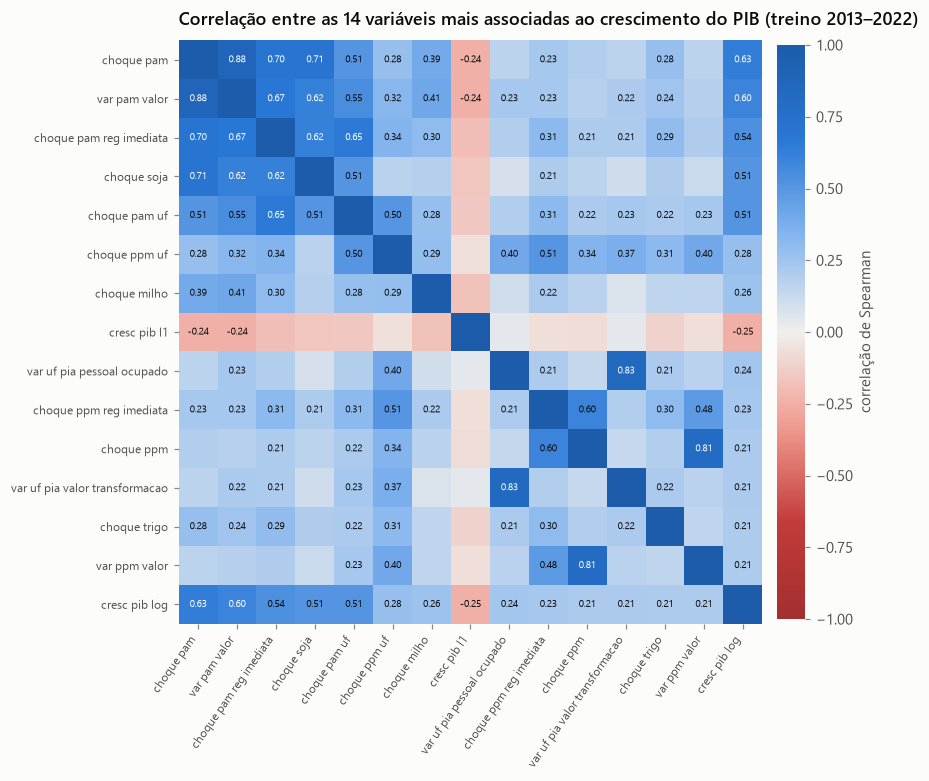

In [14]:
principais = list(corr_alvo.index[:14])
matriz = treino[principais + ["cresc_pib_log"]].corr(method="spearman")
rotulos = {c: c.replace("_", " ") for c in matriz.columns}

fig, ax = plt.subplots(figsize=(8.4, 7.2))
im = ax.imshow(matriz.to_numpy(), cmap=viz.CMAP_DIVERGENTE, vmin=-1, vmax=1)
ax.set_xticks(range(len(matriz)), [rotulos[c] for c in matriz.columns], rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(matriz)), [rotulos[c] for c in matriz.index], fontsize=8)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(matriz)):
    for j in range(len(matriz)):
        v = matriz.iat[i, j]
        if abs(v) >= 0.2 and i != j:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                    color="#ffffff" if abs(v) >= 0.6 else viz.TINTA)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("correlação de Spearman", color=viz.TINTA_SECUNDARIA)
cb.outline.set_visible(False)
ax.set_title("Correlação entre as 14 variáveis mais associadas ao crescimento do PIB (treino 2013–2022)")
fig.tight_layout()
viz.salva_figura(fig, "fig_heatmap_correlacoes")
plt.show()

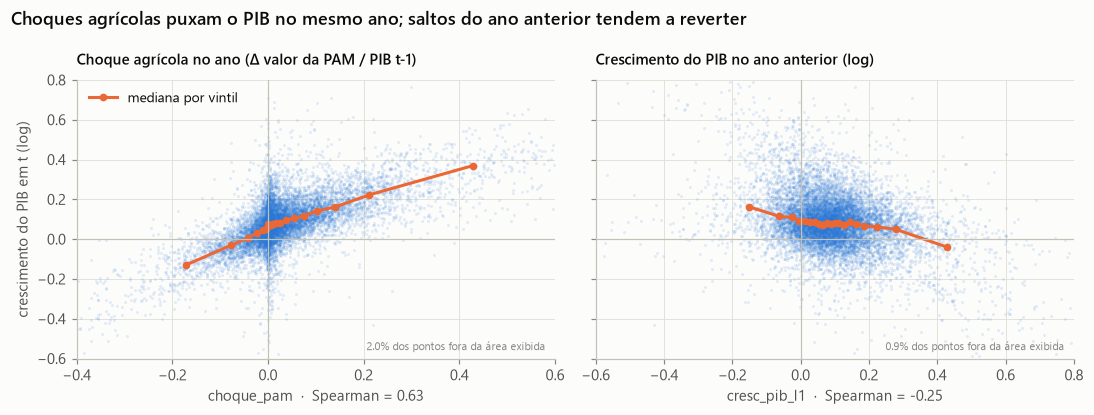

In [15]:
def medianas_por_faixa(x, y, n=20):
    faixas = pd.qcut(x, n, duplicates="drop")
    g = pd.DataFrame({"x": x, "y": y}).groupby(faixas, observed=True)
    return g["x"].median(), g["y"].median()

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
y = treino["cresc_pib_log"]
for ax, col, titulo, lim in [
    (eixos[0], "choque_pam", "Choque agrícola no ano (Δ valor da PAM / PIB t-1)", (-0.4, 0.6)),
    (eixos[1], "cresc_pib_l1", "Crescimento do PIB no ano anterior (log)", (-0.6, 0.8)),
]:
    x = treino[col]
    visivel = x.between(*lim) & y.between(-0.6, 0.8)
    ax.scatter(x[visivel], y[visivel], s=4, alpha=0.12, color=viz.RAMPA_AZUL[4], linewidths=0)
    mx, my = medianas_por_faixa(x, y)  # medianas calculadas com todos os pontos
    ax.plot(mx, my, color=viz.CATEGORICA[1], lw=2, marker="o", ms=4, label="mediana por vintil")
    ax.text(0.98, 0.03, f"{(~visivel).mean():.1%} dos pontos fora da área exibida", transform=ax.transAxes,
            ha="right", fontsize=7.5, color=viz.TINTA_SUAVE)
    ax.axhline(0, color=viz.EIXO, lw=0.8)
    ax.axvline(0, color=viz.EIXO, lw=0.8)
    ax.set_xlim(*lim)
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel(f"{col}  ·  Spearman = {corr_alvo[col]:.2f}")
eixos[0].set_ylabel("crescimento do PIB em t (log)")
eixos[0].set_ylim(-0.6, 0.8)
eixos[0].legend(loc="upper left")
fig.suptitle("Choques agrícolas puxam o PIB no mesmo ano; saltos do ano anterior tendem a reverter",
             x=0.01, ha="left", fontsize=11.5, fontweight="semibold")
fig.tight_layout()
viz.salva_figura(fig, "eda_relacoes_choque_reversao")
plt.show()

### 2.5 O que os dados de 2024 já mostram

Comparamos as variáveis do próprio ano t, que já existem para 2024, com os anos anteriores, por UF.

In [16]:
resumo_ano = (dataset[dataset["ano"].between(2019, 2024)]
              .groupby(["ano", "uf"])[["choque_pam", "choque_soja", "choque_ppm", "var_uf_pia_receita_liquida", "var_uf_pas_receita_bruta"]]
              .mean().unstack("uf"))
resumo_ano.round(3)

choque_pam               choque_soja               choque_ppm              var_uf_pia_receita_liquida               var_uf_pas_receita_bruta         \
uf           PR     RS     SC          PR     RS     SC         PR    RS     SC                         PR     RS     SC                       PR     RS   
ano                                                                                                                                                        
2019     -0.008  0.014  0.008      -0.021 -0.004 -0.000      0.002 0.005  0.005                      0.091  0.045  0.089                    0.066  0.082   
2020      0.150 -0.027  0.025       0.091 -0.030  0.006      0.017 0.019  0.025                      0.078  0.106  0.145                   -0.001 -0.072   
2021      0.147  0.361  0.051       0.109  0.272  0.024      0.006 0.018  0.020                      0.355  0.334  0.337                    0.107  0.119   
2022      0.000 -0.105  0.028      -0.054 -0.111  0.005      0.014 0.005  0.024                      0.197  0.180  0.127                    0.235  0.225   
2023      0.070 -0.002  0.027       0.084  0.007  0.013      0.004 0.002 -0.006                     -0.036 -0.061 -0.001                    0.184  0.132   
2024     -0.093  0.089 -0.025      -0.082  0.063 -0.012      0.006 0.007  0.013                      0.073  0.019  0.090                    0.141  0.131   

             
uf       SC  
ano          
2019  0.111  
2020 -0.005  
2021  0.275  
2022  0.249  
2023  0.132  
2024  0.178

## 3. Pré-processamento para os modelos

O dataset tratado guarda as variáveis **sem padronização**, para manter a interpretação.
A padronização e a codificação ficam dentro de um `Pipeline` do scikit-learn (`ft.preprocessador`), **ajustado só no conjunto de treino** e depois aplicado ao teste e à previsão. Assim nenhuma informação de 2023 ou 2024 vaza para o treino.

| Etapa | Variáveis | Transformação | Por quê |
|---|---|---|---|
| Transformação log | PIB, população e variações | `log`, `log1p` (já aplicada nas features) | PIB e população são muito assimétricos; em log, variações viram taxas |
| Razões | choques agro, participações setoriais | divisão pelo PIB ou pelo VAB | torna comparáveis municípios de tamanhos muito diferentes |
| Imputação | numéricas | mediana do treino | só restam ausentes nos 3 municípios de 2013, nos primeiros anos |
| Padronização | numéricas | `StandardScaler` (média 0, desvio 1) | necessária para modelos lineares regularizados; inócua para árvores |
| Codificação | `uf`, `regiao_intermediaria`, `porte` | one-hot | categóricas nominais; categorias novas no teste são ignoradas |

In [17]:
prep = ft.preprocessador(numericas, categoricas)
X_treino = prep.fit_transform(treino[numericas + categoricas])
teste = dataset[dataset["conjunto"] == "teste_2023"]
X_teste = prep.transform(teste[numericas + categoricas])

nomes = prep.get_feature_names_out()
print(f"Variáveis de entrada: {len(numericas)} numéricas + {len(categoricas)} categóricas")
print(f"Após o pré-processamento: {X_treino.shape[1]} colunas ({len(numericas)} numéricas + {X_treino.shape[1] - len(numericas)} dummies)")
print(f"Treino: {X_treino.shape[0]:,} linhas | Teste 2023: {X_teste.shape[0]:,} linhas")

verif = pd.DataFrame(X_treino[:, :len(numericas)], columns=nomes[:len(numericas)])
print(f"Numéricas no treino após padronização: média máx |{verif.mean().abs().max():.1e}| · desvio ∈ [{verif.std().min():.3f}, {verif.std().max():.3f}]")

Variáveis de entrada: 39 numéricas + 3 categóricas
Após o pré-processamento: 70 colunas (39 numéricas + 31 dummies)
Treino: 11,910 linhas | Teste 2023: 1,191 linhas
Numéricas no treino após padronização: média máx |2.2e-15| · desvio ∈ [1.000, 1.000]


## 4. Dataset tratado

Uma linha por **município × ano-alvo** (2008–2024). A coluna `conjunto` separa as etapas do enunciado:
- `treino`: alvos até 2022;
- `teste_2023`: Etapa A, para comparar com o PIB oficial de 2023;
- `previsao_2024`: Etapa B, alvo desconhecido.

A coluna `amostra_padrao` marca a janela de modelagem padrão (alvos ≥ 2013).

In [18]:
dataset.to_csv(ft.ARQ_DATASET, index=False, encoding="utf-8")
dicionario.to_csv(ft.ARQ_DICIONARIO_DATASET, index=False, encoding="utf-8")
print(f"Gravado: {ft.ARQ_DATASET.name} ({dataset.shape[0]:,} × {dataset.shape[1]}) e {ft.ARQ_DICIONARIO_DATASET.name}")

display(pd.crosstab(dataset["conjunto"], dataset["amostra_padrao"], margins=True))
display(dicionario.groupby(["tipo", "disponibilidade"]).size().rename("colunas").to_frame())
dicionario

Gravado: dataset_tratado.csv (20,247 × 58) e dicionario_dataset.csv


amostra_padrao,0,1,All
conjunto,,,
previsao_2024,0,1191,1191
teste_2023,0,1191,1191
treino,5955,11910,17865
All,5955,14292,20247


colunas
tipo          disponibilidade         
alvo          t                      4
categórica    fixa                   3
              t                      1
explicativa   t                     29
              t-1                    7
              t-2                    2
              t-3                    5
identificador -                      4
indicador     -                      2
              t                      1

,coluna,descricao,tipo,disponibilidade,unidade
0,cod_ibge,Código IBGE do município (7 dígitos),identificador,-,-
1,ano,Ano-alvo t (ano cujo PIB se quer prever),identificador,-,-
2,municipio,Nome do município,identificador,-,-
3,uf,Sigla da UF,categórica,fixa,-
4,cod_uf,Código IBGE da UF,identificador,-,-
5,regiao_intermediaria,Região geográfica intermediária do IBGE (21 no...,categórica,fixa,-
6,regiao_imediata,Região geográfica imediata do IBGE (96 no Sul),categórica,fixa,-
7,pib,ALVO (regressão): PIB do ano t a preços correntes,alvo,t,mil R$
8,cresc_pib_pct,ALVO auxiliar: crescimento do PIB em relação a...,alvo,t,%
9,cresc_pib_log,ALVO de treino da regressão: log(PIB_t / PIB_t-1),alvo,t,log


## 5. Conclusões parciais

**Qualidade dos dados**
- **Ausentes:** só existiam na agropecuária (0,36% das células da PAM e 23 células da PPM em 2013–2024). Foram resolvidos com interpolação nas lacunas internas e zero nos municípios sem lavouras. Não restam ausentes no período de modelagem, exceto nos 3 municípios de 2013, nos primeiros anos.
- **Duplicados:** nenhum, nem por chave (município, ano) nem em linhas inteiras.
- **Inconsistências:**
  - as identidades contábeis fecham;
  - o VAB industrial negativo de Araucária e Candiota é legítimo (refinaria e termelétrica);
  - os crescimentos extremos (até +393%) são reais, causados por grandes obras e usinas, e revertem no ano seguinte. Todos foram mantidos.
- **População:** a série tem várias quebras de base (2007/2008, 2010, 2013, 2022 e o ajuste de cobertura do Censo 2022 em 2023–2024). Depois da correção, a variação anual do Sul fica estável, entre 0,7% e 0,8%. A correlação aparente entre variação de população e crescimento do PIB **caiu de 0,20 para 0,05**: era um artefato das quebras, que coincidiam com anos atípicos.

**Análise exploratória**
- **Concentração:** o PIB municipal é muito assimétrico (assimetria de 12,9, ou 0,93 em log). Os 10 maiores municípios concentram 28% do PIB do Sul, enquanto o município mediano tem R$ 355 milhões. Por isso usamos escala log e modelamos o **crescimento**, e não o nível.
- **Crescimento nominal:** é alto e volátil (mediana de +8,7% ao ano; 1% dos casos abaixo de -28% e 1% acima de +73%). **O RS é o estado mais instável**, com estiagens em 2020 e 2022: o município gaúcho mediano encolheu 8% em 2022, depois de crescer 33% em 2021.
- **Desbalanceamento:** em 2013–2023, **64% dos casos são "Forte crescimento"**, contra 5% de "Estabilidade". A distribuição muda muito entre anos (93% de "Forte crescimento" em 2013 e 34% de "Forte retração" em 2022). Consequências: o F1 deve ser **macro** (média simples entre classes) e as classes centrais serão as mais difíceis.
- **Variáveis mais associadas ao crescimento (Spearman, treino):**
  - o **choque agrícola do ano** (`choque_pam`, 0,63; soja 0,51; milho 0,26), ou seja, a variação do valor das lavouras como fração do PIB, é de longe o melhor sinal;
  - o **mesmo choque agregado na região imediata (0,54) e na UF (0,51)** também é forte. Uma quebra de safra derruba o comércio e os serviços dos municípios vizinhos, e não só de quem planta. Essas variáveis foram incluídas depois de um diagnóstico de viés por UF na validação da Fase 4;
  - em seguida vêm a **reversão** de saltos do ano anterior (`cresc_pib_l1`, -0,25) e o contexto industrial da UF (0,21 a 0,24);
  - a estrutura setorial em t-3 quase não tem correlação monotônica sozinha, mas pode ajudar em interações (avaliado na Fase 4).
- **Sinais de 2024 já disponíveis:**
  - o choque agrícola é **negativo no PR** (-0,09, queda da soja depois do recorde de 2023) e **positivo no RS** (+0,09, recuperação da safra depois da estiagem de 2023, apesar das enchentes);
  - a receita industrial do RS cresce só 1,9%, contra 7,3% no PR e 9,0% em SC, o que é coerente com o impacto das enchentes na indústria gaúcha.

**Pré-processamento e dataset**
- **Dataset final:** 39 variáveis numéricas e 3 categóricas, que viram 70 colunas depois do one-hot. A padronização foi verificada (média 0 e desvio 1 no treino) e é sempre ajustada só no treino.
- **Variáveis do Brasil:** o dataset também traz as variações do PIB do Brasil (`var_br_*`, Contas Nacionais Trimestrais). Elas foram testadas na Fase 4 e ficaram fora do modelo por não melhorarem a validação.
- **`dataset_tratado.csv`:** 20.247 linhas × 58 colunas, com 11.910 linhas de treino na janela padrão, 1.191 de teste (2023) e 1.191 de previsão (2024). O dicionário está em `dicionario_dataset.csv`.
- **Figuras candidatas ao relatório:** `fig_categorias_por_ano` (desbalanceamento e choques por ano) e `fig_heatmap_correlacoes`.